# Variational Monte Carlo in continuous space

## From Hamiltonian symmetries to a working bosonic Monte Carlo code

In this exercise we study $N$ identical bosons in one dimension. We first implement the essential continuous-space VMC ingredients ourselves, without NetKet. We then study a harmonic well, an anharmonic quartic well, and improved trial wavefunctions.

We use units $\hbar=m=1$ throughout. The required calculations concern non-interacting bosons; interactions and fermions are discussed as extensions at the end.

## 1. Particles, Hamiltonian symmetries, boundary conditions, and the VMC estimator

For non-interacting particles,

$$
H=\sum_{i=1}^N\left[-\frac12\frac{\partial^2}{\partial x_i^2}+V(x_i)\right].
$$

The particles move on the full real line, $x_i\in(-\infty,\infty)$. There are no hard-wall boundary conditions in the harmonic or quartic problems. The physical boundary condition is normalizability,
$$
\int d\mathbf{x}\,|\Psi(\mathbf{x})|^2=1,
$$
and the wavefunction must vanish sufficiently rapidly when any $|x_i|\to\infty$. For these smooth confining potentials, admissible wavefunctions are also smooth.

The labels $i=1,\ldots,N$ identify coordinates in the mathematical description. They do not necessarily identify experimentally distinguishable particles. Identical particles have the same mass and the same interactions with the external potential, so exchanging two of them cannot change a physical prediction. Quantum mechanics implements this indistinguishability through exchange symmetry:

$$\Psi(\ldots,x_i,\ldots,x_j,\ldots)=\begin{cases}
+\Psi(\ldots,x_j,\ldots,x_i,\ldots) & \text{for bosons},\\
-\Psi(\ldots,x_j,\ldots,x_i,\ldots) & \text{for fermions}.
\end{cases}$$

Here we study bosons. The plus sign means that the wavefunction is unchanged when two particles exchange positions. Consequently, a product of identical one-body orbitals, $\Psi(\mathbf{x})=\prod_i\phi(x_i)$, is already symmetric and is a natural starting point for non-interacting bosons. Exchange effects become non-trivial when interactions or fermionic statistics change the required symmetry.

If the external potential is even, $V(-x)=V(x)$, the one-body Hamiltonian commutes with parity, $(P\psi)(x)=\psi(-x)$, so $[h,P]=0$. The many-body global parity operation is $(P\Psi)(x_1,\ldots,x_N)=\Psi(-x_1,\ldots,-x_N)$, and $[H,P]=0$ as well. Eigenstates can therefore be chosen even or odd. For these confining one-dimensional problems the ground state is non-degenerate and can be chosen even and positive: the lowest state has no nodes, and sign changes can only add kinetic energy. This is why the ground-state ansatz below uses even functions and a real log amplitude.

We represent the wavefunction through $L(\mathbf{x})=\log\Psi(\mathbf{x})$. Show that the local energy can be written as

$$
E_{\rm loc}(\mathbf{x})=\sum_i\left[-\frac12\left(\partial_i^2L+(\partial_iL)^2\right)+V(x_i)\right].
$$

This identity is the bridge between the physics and the implementation: each ansatz must provide its logarithm and its first two coordinate derivatives. Products become sums in $L$, normalization constants disappear, and wavefunction ratios become exponentials of log differences.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import typing

rng = np.random.default_rng(1234)

# plot style and colors: VMC data, analytic result, reference lines
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "axes.axisbelow": True, "lines.linewidth": 2})
C_VMC, C_EXACT, C_REF = "#2a78d6", "#eb6834", "#898781"

## 2. Continuous-space Metropolis sampling

The probability density sampled by VMC is $p(\mathbf{x})\propto|\Psi(\mathbf{x})|^2$. Propose a new configuration by changing one randomly chosen coordinate,

$$
x_i' = x_i + \delta, \qquad \delta\sim U[-\Delta,\Delta].
$$

Because this proposal is symmetric, the Metropolis acceptance probability is $\min(1,|\Psi(\mathbf{x}')|^2/|\Psi(\mathbf{x})|^2)$. Express this ratio using the logarithm of the wavefunction and implement the missing functions.

In [2]:
def metropolis_step(logpsi, x, logpsi_x, step_size, rng=rng):
    # TODO propose one-coordinate displacement and accept or reject it
    if logpsi_x is None:
        # for the sampling we work with a single sample
        # but our ansatz only supports batches
        # so we add a dummy batch dimension here
        logpsi_x = logpsi( np.expand_dims(x, 0))[0]

    index = rng.integers(x.shape[0])
    # copy: with x_prime = x both names point to the same array,
    # so a rejected move would still have modified x
    x_prime = x.copy()
    x_prime[index] = x[index] + rng.uniform(-step_size, step_size)
    logpsi_x_prime = logpsi( np.expand_dims(x_prime, 0))[0]
    # min(1, |psi(x')|^2 / |psi(x)|^2) written with the logs
    R = np.exp(min(0., 2*(logpsi_x_prime-logpsi_x)))
    accept = R > rng.random()

    if accept:
        return x_prime, logpsi_x_prime, True
    else:
        return x, logpsi_x, False


def sample_mcmc(logpsi, n_particles, n_samples, n_discard, step_size, x0=None, rng=rng, return_acceptance=False):
    # TODO return an array with shape (n_samples, n_particles)
    if x0 is None:
        x0 = rng.normal(loc=0, scale=1, size=n_particles)

    x = np.array(x0, dtype=float)
    logpsi_x = None
    n_accepted = 0

    # one sweep = n_particles single-coordinate moves, one sample is stored per sweep
    # n_discard counts the thermalization sweeps
    samples = np.empty((n_samples, n_particles))
    for sweep in range(n_discard + n_samples):
        for _ in range(n_particles):
            x, logpsi_x, accepted = metropolis_step(logpsi, x, logpsi_x, step_size, rng)
            n_accepted += accepted
        if sweep >= n_discard:
            samples[sweep - n_discard] = x

    if return_acceptance:
        return samples, n_accepted / ((n_discard + n_samples) * n_particles)
    return samples

## 3. A reusable local-energy interface

Implement a function that receives $\log\Psi$, $\nabla\log\Psi$, and $\nabla^2\log\Psi$, together with a potential and a batch of configurations. Keep the particle dimension explicit. Check that the returned local-energy array has one value per configuration.

In [3]:
def local_energy(logpsi, grad_logpsi, laplacian_logpsi, potential, x):
    # TODO support both per-particle potentials with shape (n_samples, n_particles)
    # and total potentials with shape (n_samples,)

    # grad_logpsi and laplacian_logpsi are functions of x, like logpsi and potential
    grad = grad_logpsi(x)
    lap = laplacian_logpsi(x)
    # sum over the particles only (axis=1): one value per configuration
    e_kin = -.5*np.sum(lap + grad**2, axis=1)
    V = potential(x)
    if V.ndim == 2:
        V = np.sum(V,axis=1)

    return e_kin + V

def estimate_energy(eloc, n_blocks=20):
    # TODO return the mean and standard error of correlated samples
    mean = np.mean(eloc)
    # blocking: successive samples are correlated, means over long blocks are not
    block_size = len(eloc) // n_blocks
    block_means = np.mean(eloc[:n_blocks*block_size].reshape(n_blocks, block_size), axis=1)
    err = np.std(block_means, ddof=1) / np.sqrt(n_blocks)
    return mean, err

## 4. Harmonic well

Take $V(x)=\frac12\omega^2x^2$ and use the permutation-symmetric, parity-even ansatz

$$
\log\Psi_\alpha(\mathbf{x})=-\frac{\alpha}{2}\sum_i x_i^2,\qquad \alpha>0.
$$

Derive $\partial_i\log\Psi$ and $\partial_i^2\log\Psi$. Implement them. The exact many-body ground-state energy is $E_0=N\omega/2$, and the optimum is $\alpha=\omega$.

In [4]:
def logpsi_gaussian(params, x):
    # TODO params[0] is alpha; x has shape (n_samples, n_particles)
    logpsi = - .5 * params[0] * np.sum(np.power(x, 2) ,axis = 1)
    return logpsi
    

def grad_logpsi_gaussian(params, x):
    # TODO return shape (n_samples, n_particles)
    return - params[0]*x

def laplacian_logpsi_gaussian(params, x):
    # TODO return shape (n_samples, n_particles)
    return -params[0]*np.ones_like(x)

def harmonic_potential(x, omega):
    return 0.5 * omega**2 * x**2


 alpha   E/N (VMC)          E/N (exact)   acceptance
  0.40   0.7304 +- 0.0113   0.7250        0.74
  0.60   0.5682 +- 0.0052   0.5667        0.69
  0.80   0.5110 +- 0.0017   0.5125        0.65
  1.00   0.5000 +- 0.0000   0.5000        0.61
  1.20   0.5079 +- 0.0020   0.5083        0.58
  1.40   0.5268 +- 0.0024   0.5286        0.56
  1.60   0.5555 +- 0.0029   0.5563        0.53
  1.80   0.5888 +- 0.0044   0.5889        0.51
  2.00   0.6249 +- 0.0059   0.6250        0.49
  2.20   0.6698 +- 0.0059   0.6636        0.48


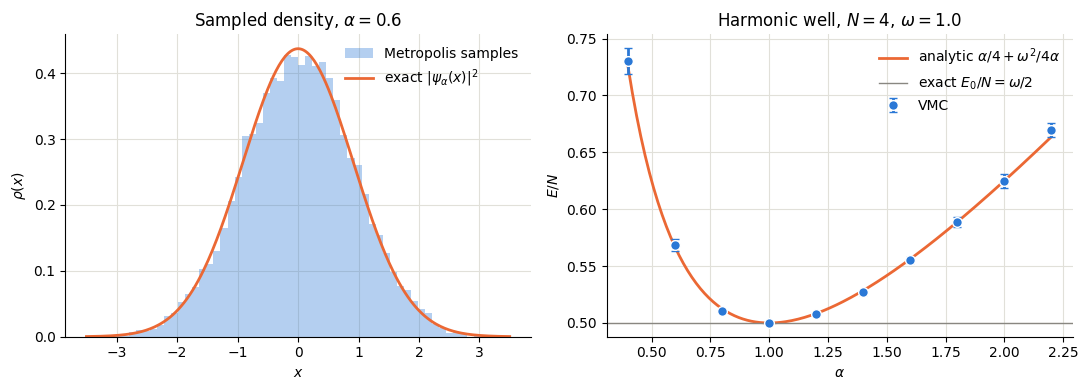

In [5]:
def vmc_gaussian(alpha, potential, n_particles, n_samples=10000, n_discard=500, step_size=1.5):
    # one VMC run at fixed alpha: samples, energy, its error and the acceptance rate
    params = np.array([alpha])
    logpsi = lambda x: logpsi_gaussian(params, x)
    grad_logpsi = lambda x: grad_logpsi_gaussian(params, x)
    laplacian_logpsi = lambda x: laplacian_logpsi_gaussian(params, x)

    x, acceptance = sample_mcmc(logpsi, n_particles, n_samples, n_discard, step_size, return_acceptance=True)
    eloc = local_energy(logpsi, grad_logpsi, laplacian_logpsi, potential, x)
    energy, err = estimate_energy(eloc)
    return x, energy, err, acceptance


omega = 1.0
n_particles = 4
potential = lambda x: harmonic_potential(x, omega)

alphas = np.linspace(0.4, 2.2, 10)
runs = [vmc_gaussian(alpha, potential, n_particles) for alpha in alphas]
energies = np.array([run[1] for run in runs]) / n_particles
errors = np.array([run[2] for run in runs]) / n_particles

print(" alpha   E/N (VMC)          E/N (exact)   acceptance")
for alpha, (x, energy, err, acceptance) in zip(alphas, runs):
    exact = alpha/4 + omega**2/(4*alpha)
    print(f"{alpha:6.2f}   {energy/n_particles:.4f} +- {err/n_particles:.4f}   {exact:.4f}        {acceptance:.2f}")

fig, (ax_rho, ax_E) = plt.subplots(1, 2, figsize=(11, 4))

# sampler check: the positions must be distributed as |psi|^2 = sqrt(alpha/pi) exp(-alpha x^2)
alpha_check, x_check = alphas[1], runs[1][0]
grid = np.linspace(-3.5, 3.5, 300)
ax_rho.hist(x_check.ravel(), bins=60, range=(-3.5, 3.5), density=True, color=C_VMC, alpha=0.35, label="Metropolis samples")
ax_rho.plot(grid, np.sqrt(alpha_check/np.pi)*np.exp(-alpha_check*grid**2), color=C_EXACT, label=r"exact $|\psi_\alpha(x)|^2$")
ax_rho.set(xlabel="$x$", ylabel=r"$\rho(x)$", title=rf"Sampled density, $\alpha={alpha_check:.1f}$")
ax_rho.legend(frameon=False)

alpha_grid = np.linspace(alphas[0], alphas[-1], 200)
ax_E.plot(alpha_grid, alpha_grid/4 + omega**2/(4*alpha_grid), color=C_EXACT, label=r"analytic $\alpha/4+\omega^2/4\alpha$")
ax_E.axhline(omega/2, color=C_REF, linewidth=1, label=r"exact $E_0/N=\omega/2$")
ax_E.errorbar(alphas, energies, yerr=errors, fmt="o", color=C_VMC, markersize=7, markeredgecolor="white", capsize=3, label="VMC")
ax_E.set(xlabel=r"$\alpha$", ylabel="$E/N$", title=rf"Harmonic well, $N={n_particles}$, $\omega={omega}$")
ax_E.legend(frameon=False)

fig.tight_layout()
plt.show()

## 5. Variational optimization

For a real positive ansatz define $O_k=\partial_{\theta_k}\log\Psi$. Derive and implement

$$
\frac{\partial E}{\partial\theta_k}=2\left(\langle E_{\rm loc}O_k\rangle-\langle E_{\rm loc}\rangle\langle O_k\rangle\right).
$$

For the one-parameter Gaussian, $O_\alpha=-\frac12\sum_i x_i^2$. Use gradient descent, while enforcing $\alpha>0$.

In [6]:
def gaussian_parameter_gradient(params, x, eloc):
    # TODO implement the covariance estimator
    O = -.5*np.sum(np.power(x,2), axis=1)
    # np.cov(eloc, O) is the whole 2x2 covariance matrix, we need only its off-diagonal element
    grad_E = 2*(np.mean(eloc*O) - np.mean(eloc)*np.mean(O))
    return np.array([grad_E])

def optimize_gaussian(omega, n_particles, n_steps=100, alpha0=0.5, lr=0.2, n_samples=1000, n_discard=150, step_size=1.5):
    # TODO sample, estimate energy, compute gradient, and update alpha
    params = np.array([alpha0], dtype=float)
    potential = lambda x: harmonic_potential(x, omega)
    history = {"alpha": [], "energy": [], "error": []}
    x0 = None

    for step in range(n_steps):
        logpsi = lambda x: logpsi_gaussian(params, x)
        grad_logpsi = lambda x: grad_logpsi_gaussian(params, x)
        laplacian_logpsi = lambda x: laplacian_logpsi_gaussian(params, x)

        x = sample_mcmc(logpsi, n_particles, n_samples, n_discard, step_size, x0=x0)
        eloc = local_energy(logpsi, grad_logpsi, laplacian_logpsi, potential, x)
        energy, err = estimate_energy(eloc)
        history["alpha"].append(params[0])
        history["energy"].append(energy)
        history["error"].append(err)

        grad = gaussian_parameter_gradient(params, x, eloc)
        # the gradient grows like N: dividing by N the same lr works for every N
        # alpha must stay positive, otherwise psi is not normalizable
        params = np.maximum(params - lr*grad/n_particles, 1e-3)
        # the next chain starts from the last configuration of this one
        x0 = x[-1]

    return params, {key: np.array(values) for key, values in history.items()}

final alpha = 1.0000   (exact 1.0)
final E/N   = 0.50000 +- 0.00000   (exact 0.5)


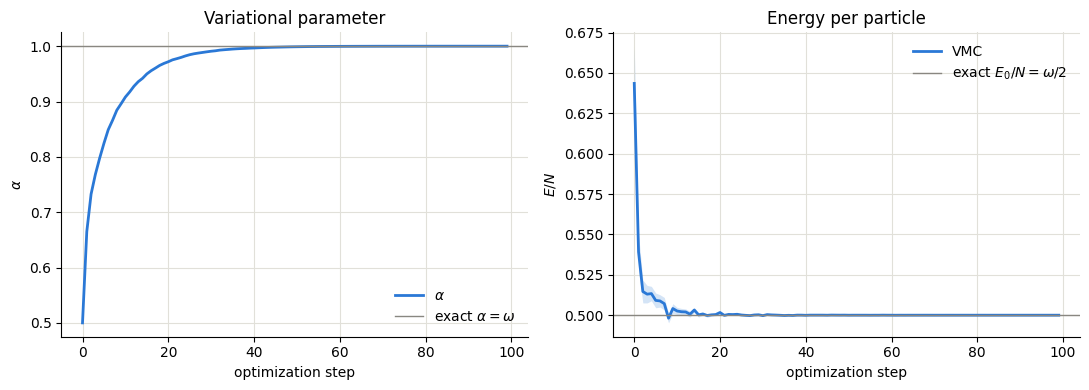

In [7]:
omega = 1.0
n_particles = 4

params, history = optimize_gaussian(omega, n_particles, n_steps=100, alpha0=0.5)
print(f"final alpha = {params[0]:.4f}   (exact {omega})")
print(f"final E/N   = {history['energy'][-1]/n_particles:.5f} +- {history['error'][-1]/n_particles:.5f}   (exact {omega/2})")

steps = np.arange(len(history["alpha"]))
energy = history["energy"] / n_particles
error = history["error"] / n_particles

fig, (ax_alpha, ax_E) = plt.subplots(1, 2, figsize=(11, 4))

ax_alpha.plot(steps, history["alpha"], color=C_VMC, label=r"$\alpha$")
ax_alpha.axhline(omega, color=C_REF, linewidth=1, label=r"exact $\alpha=\omega$")
ax_alpha.set(xlabel="optimization step", ylabel=r"$\alpha$", title="Variational parameter")
ax_alpha.legend(frameon=False)

ax_E.plot(steps, energy, color=C_VMC, label="VMC")
ax_E.fill_between(steps, energy - error, energy + error, color=C_VMC, alpha=0.2, linewidth=0)
ax_E.axhline(omega/2, color=C_REF, linewidth=1, label=r"exact $E_0/N=\omega/2$")
ax_E.set(xlabel="optimization step", ylabel="$E/N$", title="Energy per particle")
ax_E.legend(frameon=False)

fig.tight_layout()
plt.show()

## 6. Quartic anharmonic well

Now take $V(x)=\lambda x^4$. First reuse the Gaussian ansatz. Show that

$$
\frac{E(\alpha)}{N}=\frac{\alpha}{4}+\frac{3\lambda}{4\alpha^2},\qquad \alpha_{\rm opt}=(6\lambda)^{1/3}.
$$

There is no elementary closed-form formula for the quartic ground-state energy. However, the energy can be known to high accuracy by solving the one-dimensional Schrodinger equation numerically. For $\lambda=1$, a trusted numerical benchmark is $E_0^{(1)}\simeq0.667986$. Use the scaling $E_0^{(1)}(\lambda)=\lambda^{1/3}E_0^{(1)}(1)$ and compare it with VMC. Explain why this value is a numerical benchmark rather than an exact closed-form expression.

alpha_opt = (6 lambda)^(1/3)     = 1.8171
E/N VMC at alpha_opt             = 0.6818 +- 0.0028   (acceptance 0.51)
E/N Gaussian prediction          = 0.6814
E/N numerical benchmark          = 0.6680
Gaussian ansatz above benchmark  = 2.0 %


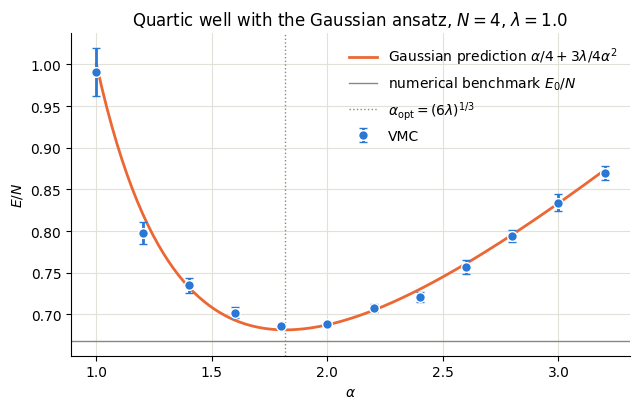

In [8]:
def quartic_potential(x, lam):
    return lam * x**4

# TODO run VMC for the quartic potential and compare with the Gaussian
# variational prediction and the numerical benchmark.
lam = 1.0
n_particles = 4
potential = lambda x: quartic_potential(x, lam)

alpha_opt = (6*lam)**(1/3)
benchmark = 0.667986 * lam**(1/3)

alphas = np.linspace(1.0, 3.2, 12)
runs = [vmc_gaussian(alpha, potential, n_particles) for alpha in alphas]
energies = np.array([run[1] for run in runs]) / n_particles
errors = np.array([run[2] for run in runs]) / n_particles

# longer run at the optimal alpha
x, energy_opt, err_opt, acceptance = vmc_gaussian(alpha_opt, potential, n_particles, n_samples=20000)
energy_opt, err_opt = energy_opt/n_particles, err_opt/n_particles
gaussian_min = alpha_opt/4 + 3*lam/(4*alpha_opt**2)

print(f"alpha_opt = (6 lambda)^(1/3)     = {alpha_opt:.4f}")
print(f"E/N VMC at alpha_opt             = {energy_opt:.4f} +- {err_opt:.4f}   (acceptance {acceptance:.2f})")
print(f"E/N Gaussian prediction          = {gaussian_min:.4f}")
print(f"E/N numerical benchmark          = {benchmark:.4f}")
print(f"Gaussian ansatz above benchmark  = {100*(gaussian_min/benchmark - 1):.1f} %")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
alpha_grid = np.linspace(alphas[0], alphas[-1], 200)
ax.plot(alpha_grid, alpha_grid/4 + 3*lam/(4*alpha_grid**2), color=C_EXACT, label=r"Gaussian prediction $\alpha/4+3\lambda/4\alpha^2$")
ax.axhline(benchmark, color=C_REF, linewidth=1, label="numerical benchmark $E_0/N$")
ax.axvline(alpha_opt, color=C_REF, linewidth=1, linestyle=":", label=r"$\alpha_{\rm opt}=(6\lambda)^{1/3}$")
ax.errorbar(alphas, energies, yerr=errors, fmt="o", color=C_VMC, markersize=7, markeredgecolor="white", capsize=3, label="VMC")
ax.set(xlabel=r"$\alpha$", ylabel="$E/N$", title=rf"Quartic well with the Gaussian ansatz, $N={n_particles}$, $\lambda={lam}$")
ax.legend(frameon=False)

fig.tight_layout()
plt.show()

## 7. Improved trial wavefunction

Use the symmetry-preserving ansatz

$$
\log\Psi_{a,b}(\mathbf{x})=-\sum_i\left(\frac{a}{2}x_i^2+b x_i^4\right).
$$

Explain why it is bosonic and parity even, and why normalizability requires $b>0$. Implement its coordinate derivatives and parameter derivatives. Optimize $a$ and $b$, then compare the result against the Gaussian and the numerical benchmark.

**Symmetry and normalizability.** $\log\Psi_{a,b}=\sum_i f(x_i)$ with the same one-body function $f(x)=-\frac a2x^2-bx^4$ for every particle, so any permutation of the coordinates only reorders the terms of the sum: $\Psi_{a,b}$ is symmetric (bosonic). $f$ contains only even powers, so $f(-x)=f(x)$ and $\Psi_{a,b}(-\mathbf{x})=\Psi_{a,b}(\mathbf{x})$ (parity even).

For large $|x|$ the quartic term dominates, $|\Psi|^2\sim e^{-2bx^4}$. With $b>0$ this decays faster than any Gaussian, so $\int|\Psi|^2$ is finite for any sign of $a$; with $b<0$ it grows like $e^{+2|b|x^4}$ and cannot be normalized. ($b=0$ is the Gaussian, which needs $a>0$.) The optimizer therefore keeps $b>0$ and leaves $a$ free.

The $x^4$ term helps because the exact ground state decays like $e^{-\sqrt{2\lambda}|x|^3/3}$ (WKB), faster than a Gaussian: the improved ansatz can have a flatter center and steeper tails.

In [9]:
def logpsi_quartic(params, x):
    # TODO implement the improved log wavefunction
    a, b = params
    return -np.sum(a/2*np.power(x, 2) + b*np.power(x, 4), axis=1)

def grad_logpsi_quartic(params, x):
    # TODO coordinate gradient
    a, b = params
    return -a*x - 4*b*np.power(x, 3)

def laplacian_logpsi_quartic(params, x):
    # TODO second coordinate derivative
    a, b = params
    return -a - 12*b*np.power(x, 2)

def parameter_loggrad_quartic(params, x):
    # TODO return shape (n_samples, 2)
    # O_a = dlogpsi/da and O_b = dlogpsi/db
    O_a = -.5*np.sum(np.power(x, 2), axis=1)
    O_b = -np.sum(np.power(x, 4), axis=1)
    return np.stack([O_a, O_b], axis=1)

In [10]:
def sr_update(O, eloc, diag_shift=1e-3):
    # stochastic reconfiguration: solve (S + diag_shift) delta = F with
    # S_kl = <O_k O_l> - <O_k><O_l> and F_k = <eloc O_k> - <eloc><O_k> = (dE/dtheta_k)/2
    O_c = O - np.mean(O, axis=0)
    S = O_c.T @ O_c / len(eloc)
    F = O_c.T @ (eloc - np.mean(eloc)) / len(eloc)
    return np.linalg.solve(S + diag_shift*np.eye(len(F)), F)

def optimize_quartic(lam, n_particles, params0, n_steps=100, lr=0.1, n_samples=1000, n_discard=150, step_size=1.5):
    params = np.array(params0, dtype=float)
    potential = lambda x: quartic_potential(x, lam)
    history = {"a": [], "b": [], "energy": [], "error": []}
    x0 = None

    for step in range(n_steps):
        logpsi = lambda x: logpsi_quartic(params, x)
        grad_logpsi = lambda x: grad_logpsi_quartic(params, x)
        laplacian_logpsi = lambda x: laplacian_logpsi_quartic(params, x)

        x = sample_mcmc(logpsi, n_particles, n_samples, n_discard, step_size, x0=x0)
        eloc = local_energy(logpsi, grad_logpsi, laplacian_logpsi, potential, x)
        energy, err = estimate_energy(eloc)
        history["a"].append(params[0])
        history["b"].append(params[1])
        history["energy"].append(energy)
        history["error"].append(err)

        params = params - lr*sr_update(parameter_loggrad_quartic(params, x), eloc)
        # b > 0 keeps psi normalizable, a can have any sign
        params[1] = max(params[1], 1e-6)
        x0 = x[-1]

    return params, {key: np.array(values) for key, values in history.items()}

optimal a = 1.3708, b = 0.1203
                          E/N                    above benchmark
best Gaussian (exact)     0.68142                2.01 %
improved ansatz (VMC)     0.66836 +- 0.00011    0.06 +- 0.02 %
numerical benchmark       0.66799


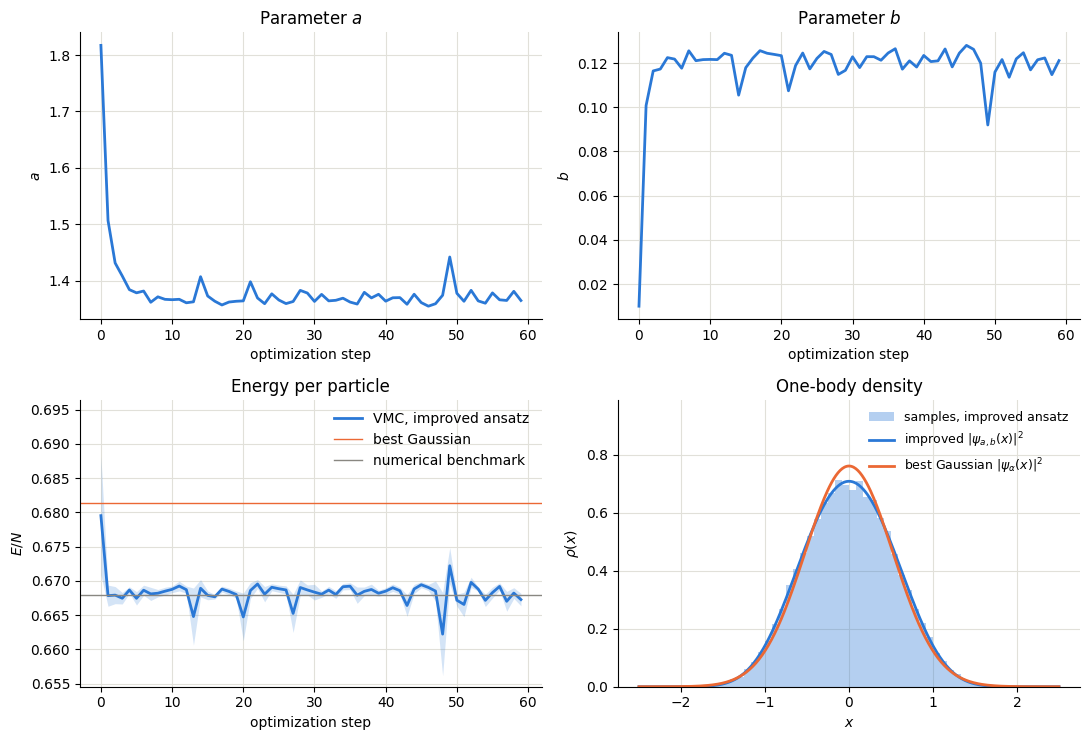

In [11]:
lam = 1.0
n_particles = 4
potential = lambda x: quartic_potential(x, lam)
benchmark = 0.667986 * lam**(1/3)
alpha_opt = (6*lam)**(1/3)
gaussian_min = 3*alpha_opt/8

# start from the best Gaussian, with a small quartic term
params, history = optimize_quartic(lam, n_particles, params0=(alpha_opt, 0.01), n_steps=60, lr=0.1)

# a and b fluctuate around the optimum: average them over the last 30 steps,
# then use one long run for the energy (the error bars of the short runs are less reliable)
params_opt = np.array([np.mean(history["a"][-30:]), np.mean(history["b"][-30:])])
logpsi = lambda x: logpsi_quartic(params_opt, x)
grad_logpsi = lambda x: grad_logpsi_quartic(params_opt, x)
laplacian_logpsi = lambda x: laplacian_logpsi_quartic(params_opt, x)
x_improved = sample_mcmc(logpsi, n_particles, 40000, 500, 1.5)
eloc = local_energy(logpsi, grad_logpsi, laplacian_logpsi, potential, x_improved)
energy_improved, err_improved = estimate_energy(eloc)
energy_improved, err_improved = energy_improved/n_particles, err_improved/n_particles

print(f"optimal a = {params_opt[0]:.4f}, b = {params_opt[1]:.4f}")
print(f"                          E/N                    above benchmark")
print(f"best Gaussian (exact)     {gaussian_min:.5f}                {100*(gaussian_min/benchmark - 1):.2f} %")
print(f"improved ansatz (VMC)     {energy_improved:.5f} +- {err_improved:.5f}    {100*(energy_improved/benchmark - 1):.2f} +- {100*err_improved/benchmark:.2f} %")
print(f"numerical benchmark       {benchmark:.5f}")

steps = np.arange(len(history["a"]))
energy = history["energy"] / n_particles
error = history["error"] / n_particles

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
(ax_a, ax_b), (ax_E, ax_rho) = axes

ax_a.plot(steps, history["a"], color=C_VMC)
ax_a.set(xlabel="optimization step", ylabel="$a$", title="Parameter $a$")
ax_b.plot(steps, history["b"], color=C_VMC)
ax_b.set(xlabel="optimization step", ylabel="$b$", title="Parameter $b$")

ax_E.plot(steps, energy, color=C_VMC, label="VMC, improved ansatz")
ax_E.fill_between(steps, energy - error, energy + error, color=C_VMC, alpha=0.2, linewidth=0)
ax_E.axhline(gaussian_min, color=C_EXACT, linewidth=1, label="best Gaussian")
ax_E.axhline(benchmark, color=C_REF, linewidth=1, label="numerical benchmark")
ax_E.set(xlabel="optimization step", ylabel="$E/N$", title="Energy per particle")
ax_E.set_ylim(top=gaussian_min + 0.015)
ax_E.legend(frameon=False)

# one-body densities |psi|^2 of the two optimized ansatzes, normalized on a grid
grid = np.linspace(-2.5, 2.5, 400)
rho_improved = np.exp(2*logpsi_quartic(params_opt, grid[:, None]))
rho_improved /= np.sum(rho_improved) * (grid[1] - grid[0])
rho_gaussian = np.sqrt(alpha_opt/np.pi) * np.exp(-alpha_opt*grid**2)
ax_rho.hist(x_improved.ravel(), bins=60, range=(-2.5, 2.5), density=True, color=C_VMC, alpha=0.35, label="samples, improved ansatz")
ax_rho.plot(grid, rho_improved, color=C_VMC, label=r"improved $|\psi_{a,b}(x)|^2$")
ax_rho.plot(grid, rho_gaussian, color=C_EXACT, label=r"best Gaussian $|\psi_\alpha(x)|^2$")
ax_rho.set(xlabel="$x$", ylabel=r"$\rho(x)$", title="One-body density")
ax_rho.set_ylim(0, 1.3*rho_gaussian.max())
ax_rho.legend(frameon=False, loc="upper right", fontsize=9)

fig.tight_layout()
plt.show()

## 8. Interacting bosons: a finite-range Gaussian repulsion

Go beyond independent particles by adding a smooth repulsion to the harmonic trap:

$$
H=\sum_i\left[-\frac12\partial_i^2+\frac12\omega^2x_i^2\right]+\sum_{i<j}U(x_i-x_j).
$$

Use the finite-range Gaussian interaction

$$
U(r)=g\exp\left[-\frac{r^2}{2\sigma^2}\right],\qquad g>0.
$$

This interaction is large when particles are close. It is finite-range and smooth, so it avoids the singular derivatives associated with a contact interaction. The interaction energy is one number per configuration:

$$
V_{\mathrm{int}}(\mathbf{x})=\sum_{i<j}U(x_i-x_j).
$$

The product Gaussian is still bosonic, but it cannot describe correlations efficiently. Use the symmetric Jastrow-improved ansatz

$$
\log\Psi(\mathbf{x})=-\frac{a}{2}\sum_i x_i^2-c\sum_{i<j}\exp\left[-\frac{(x_i-x_j)^2}{2\ell^2}\right].
$$

The pair sum is unchanged by exchanging particles. Implement the pair interaction, the Jastrow log wavefunction, and its first and second coordinate derivatives. Compare the product Gaussian and Jastrow energies as the repulsion strength $g$ is increased. Check that the pair-distance distribution is suppressed near zero.

In [12]:
def pair_gaussians(x, width):
    # r[s, i, j] = x_i - x_j in configuration s, and exp(-r^2 / (2 width^2)) for every pair
    r = x[:, :, None] - x[:, None, :]
    return r, np.exp(-np.power(r,2)/(2*width**2))

def gaussian_pair_interaction(x, interaction_strength, interaction_range):
    # TODO return the total pair interaction for each configuration
    N = x.shape[1]
    r, u = pair_gaussians(x, interaction_range)
    # the full matrix counts every pair twice and has N diagonal terms equal to 1
    return interaction_strength*.5*(np.sum(u, axis=(1,2)) - N)

def interacting_harmonic_potential(x, omega, interaction_strength, interaction_range):
    # TODO add the harmonic trap energy and pair interaction energy
    U = gaussian_pair_interaction(x,interaction_strength,interaction_range)
    return U + .5*omega**2*np.sum(np.power(x,2), axis=1)

def logpsi_interacting(raw_params, x, jastrow_range):
    # TODO implement the symmetric one-body plus Jastrow log wavefunction
    # raw_params = (a, c)
    N = x.shape[1]
    r, u = pair_gaussians(x, jastrow_range)
    L = -.5*raw_params[0]*np.sum(np.power(x,2),axis=1) - raw_params[1]*.5*(np.sum(u, axis=(1,2)) - N)
    return L

def grad_logpsi_interacting(raw_params, x, jastrow_range):
    # TODO return the first derivative with respect to every particle coordinate
    r, u = pair_gaussians(x, jastrow_range)
    # d/dx_k of u(x_k - x_j) is -r_kj u_kj / l^2, the term j = k vanishes because r_kk = 0
    return -raw_params[0]*x + raw_params[1]/jastrow_range**2*np.sum(r*u, axis=2)

def laplacian_logpsi_interacting(raw_params, x, jastrow_range):
    # TODO return the second derivative with respect to every particle coordinate
    r, u = pair_gaussians(x, jastrow_range)
    # d2/dx_k2 of u(x_k - x_j) is (r_kj^2/l^2 - 1) u_kj / l^2, the term j = k of the sum is 1 and is removed
    return -raw_params[0] + raw_params[1]/jastrow_range**2*(np.sum((1 - np.power(r,2)/jastrow_range**2)*u, axis=2) - 1)

def parameter_loggrad_interacting(raw_params, x, jastrow_range):
    # O_a = dlogpsi/da and O_c = dlogpsi/dc, shape (n_samples, 2)
    N = x.shape[1]
    r, u = pair_gaussians(x, jastrow_range)
    O_a = -.5*np.sum(np.power(x,2), axis=1)
    O_c = -.5*(np.sum(u, axis=(1,2)) - N)
    return np.stack([O_a, O_c], axis=1)

In [13]:
def optimize_interacting(omega, interaction_strength, interaction_range, jastrow_range, n_particles, raw_params0,
                         optimize_jastrow=True, n_steps=20, lr=0.2, n_samples=1000, n_discard=150, step_size=1.5):
    raw_params = np.array(raw_params0, dtype=float)
    potential = lambda x: interacting_harmonic_potential(x, omega, interaction_strength, interaction_range)
    history = {"a": [], "c": [], "energy": [], "error": []}
    x0 = None

    for step in range(n_steps):
        logpsi = lambda x: logpsi_interacting(raw_params, x, jastrow_range)
        grad_logpsi = lambda x: grad_logpsi_interacting(raw_params, x, jastrow_range)
        laplacian_logpsi = lambda x: laplacian_logpsi_interacting(raw_params, x, jastrow_range)

        x = sample_mcmc(logpsi, n_particles, n_samples, n_discard, step_size, x0=x0)
        eloc = local_energy(logpsi, grad_logpsi, laplacian_logpsi, potential, x)
        energy, err = estimate_energy(eloc)
        history["a"].append(raw_params[0])
        history["c"].append(raw_params[1])
        history["energy"].append(energy)
        history["error"].append(err)

        O = parameter_loggrad_interacting(raw_params, x, jastrow_range)
        if not optimize_jastrow:
            # product Gaussian: only a is optimized, c keeps its initial value
            O = O[:, :1]
        raw_params[:O.shape[1]] -= lr*sr_update(O, eloc)
        # a > 0 keeps psi normalizable, c can have any sign
        raw_params[0] = max(raw_params[0], 1e-3)
        x0 = x[-1]

    return raw_params, {key: np.array(values) for key, values in history.items()}

def vmc_interacting(raw_params, potential, n_particles, jastrow_range, n_samples=20000, n_discard=500, step_size=1.5):
    # one long VMC run at fixed parameters: samples, energy and its error
    logpsi = lambda x: logpsi_interacting(raw_params, x, jastrow_range)
    grad_logpsi = lambda x: grad_logpsi_interacting(raw_params, x, jastrow_range)
    laplacian_logpsi = lambda x: laplacian_logpsi_interacting(raw_params, x, jastrow_range)

    x = sample_mcmc(logpsi, n_particles, n_samples, n_discard, step_size)
    eloc = local_energy(logpsi, grad_logpsi, laplacian_logpsi, potential, x)
    energy, err = estimate_energy(eloc)
    return x, energy, err

    g   product: a     E                 Jastrow: a      c      E                 E_product - E_Jastrow
 0.00        1.000     2.0000 +- 0.0000        1.000  -0.000  2.0000 +- 0.0000   0.0000 +- 0.0000
 0.25        0.877     2.6506 +- 0.0025        0.986  0.114  2.6412 +- 0.0004   0.0094 +- 0.0026
 0.50        0.772     3.2743 +- 0.0038        0.974  0.227  3.2269 +- 0.0009   0.0475 +- 0.0039
 1.00        0.623     4.4394 +- 0.0083        0.944  0.442  4.2461 +- 0.0016   0.1933 +- 0.0084
 2.00        0.460     6.4987 +- 0.0185        0.891  0.809  5.8387 +- 0.0046   0.6600 +- 0.0191


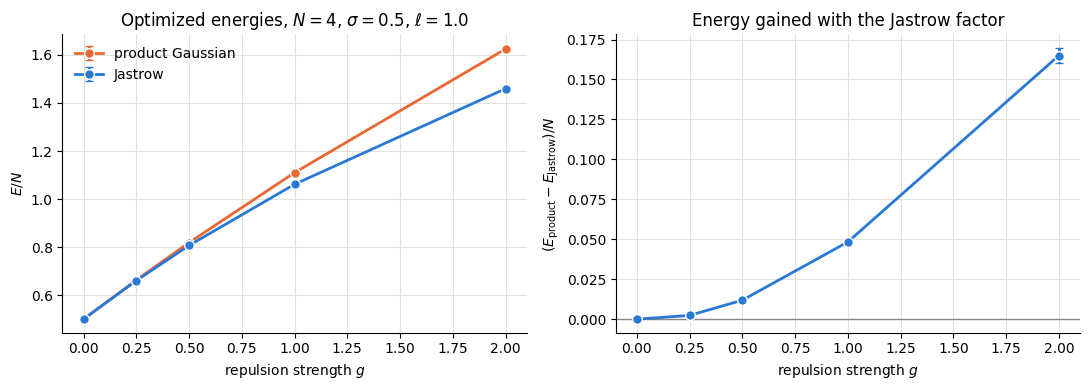

In [14]:
omega = 1.0
n_particles = 4
interaction_range = 0.5
# fixed range of the Jastrow factor: the oscillator length gives a lower energy than interaction_range
jastrow_range = 1.0
coupling_values = np.array([0.0, 0.25, 0.5, 1.0, 2.0])

# TODO sample the interacting system and compare the product and Jastrow ansatzes.
# For every coupling both ansatzes are optimized (starting from the optimum of the previous coupling,
# parameters averaged over the last 10 steps) and then sampled in one long run.
# The product Gaussian is the same wavefunction with c fixed to 0.
product_params, jastrow_params = [], []
product_runs, jastrow_runs = [], []
raw_product, raw_jastrow = np.array([omega, 0.0]), np.array([omega, 0.0])
for g in coupling_values:
    potential = lambda x: interacting_harmonic_potential(x, omega, g, interaction_range)

    _, history = optimize_interacting(omega, g, interaction_range, jastrow_range, n_particles, raw_product, optimize_jastrow=False)
    raw_product = np.array([np.mean(history["a"][-10:]), 0.0])
    _, history = optimize_interacting(omega, g, interaction_range, jastrow_range, n_particles, raw_jastrow)
    raw_jastrow = np.array([np.mean(history["a"][-10:]), np.mean(history["c"][-10:])])

    product_params.append(raw_product)
    jastrow_params.append(raw_jastrow)
    product_runs.append(vmc_interacting(raw_product, potential, n_particles, jastrow_range))
    jastrow_runs.append(vmc_interacting(raw_jastrow, potential, n_particles, jastrow_range))

product_energy = np.array([run[1] for run in product_runs])
product_error = np.array([run[2] for run in product_runs])
jastrow_energy = np.array([run[1] for run in jastrow_runs])
jastrow_error = np.array([run[2] for run in jastrow_runs])
gain = product_energy - jastrow_energy
gain_error = np.sqrt(product_error**2 + jastrow_error**2)

print("    g   product: a     E                 Jastrow: a      c      E                 E_product - E_Jastrow")
for k, g in enumerate(coupling_values):
    print(f"{g:5.2f}   {product_params[k][0]:10.3f}     {product_energy[k]:.4f} +- {product_error[k]:.4f}"
          f"   {jastrow_params[k][0]:10.3f}  {jastrow_params[k][1]:5.3f}  {jastrow_energy[k]:.4f} +- {jastrow_error[k]:.4f}"
          f"   {gain[k]:.4f} +- {gain_error[k]:.4f}")

fig, (ax_E, ax_gain) = plt.subplots(1, 2, figsize=(11, 4))

ax_E.errorbar(coupling_values, product_energy/n_particles, yerr=product_error/n_particles, fmt="o-", color=C_EXACT, markersize=7, markeredgecolor="white", capsize=3, label="product Gaussian")
ax_E.errorbar(coupling_values, jastrow_energy/n_particles, yerr=jastrow_error/n_particles, fmt="o-", color=C_VMC, markersize=7, markeredgecolor="white", capsize=3, label="Jastrow")
ax_E.set(xlabel="repulsion strength $g$", ylabel="$E/N$", title=rf"Optimized energies, $N={n_particles}$, $\sigma={interaction_range}$, $\ell={jastrow_range}$")
ax_E.legend(frameon=False)

ax_gain.axhline(0, color=C_REF, linewidth=1)
ax_gain.errorbar(coupling_values, gain/n_particles, yerr=gain_error/n_particles, fmt="o-", color=C_VMC, markersize=7, markeredgecolor="white", capsize=3)
ax_gain.set(xlabel="repulsion strength $g$", ylabel=r"$(E_{\rm product}-E_{\rm Jastrow})/N$", title="Energy gained with the Jastrow factor")

fig.tight_layout()
plt.show()

**Product vs Jastrow.** At $g=0$ the product Gaussian with $a=\omega$ is the exact ground state: the optimizer returns $c=0$ and both energies equal $N\omega/2$ with zero variance. For $g>0$ the product Gaussian can only lower $a$, which widens the whole cloud (from $a=1$ to $a\approx0.46$ at $g=2$). The Jastrow factor keeps $a$ close to $\omega$ and lowers the energy further by keeping the particles apart. The gain grows faster than linearly with $g$ and reaches about 10% of the total energy at $g=2$ (about $0.66$ out of $6.5$).

## 9. Ground-state analysis: four observables

Use four observables to interpret the sampled ground state.

1. **One-body density**

   $$
   \rho(x)=\frac{1}{N}\left\langle\sum_i\delta(x-x_i)\right\rangle.
   $$

   Show that for samples $\mathbf{x}^{(s)}\sim|\Psi|^2$,

   $$
   \rho(x)\approx\frac{1}{N_sN}\sum_{s=1}^{N_s}\sum_i\delta(x-x_i^{(s)}).
   $$

2. **Pair-distance distribution**

   For $r\geq0$, define

   $$
   P(r)=\frac{2}{N(N-1)}\left\langle\sum_{i<j}\delta\left(r-|x_i-x_j|\right)\right\rangle.
   $$

   Explain the normalization:

   $$
   \int_0^\infty P(r)\,dr=1.
   $$

   Then derive the Monte Carlo estimator

   $$
   P(r)\approx\frac{2}{N_sN(N-1)}\sum_{s=1}^{N_s}\sum_{i<j}\delta\left(r-|x_i^{(s)}-x_j^{(s)}|\right).
   $$

   Explain how replacing each delta function by a histogram bin leads to `np.histogram(..., density=True)`.

3. **Cloud size**

   $$
   \langle x^2\rangle=\frac{1}{N}\left\langle\sum_i x_i^2\right\rangle.
   $$

   Implement its sample average.

4. **Close-pair probability**

   $$
   P(r<\sigma)=\int_0^\sigma P(r)\,dr.
   $$

   Show that it is estimated by the fraction of sampled unordered pairs with $|x_i-x_j|<\sigma$.

Use these observables in the 2x2 panel. Explain why increasing repulsion should broaden $\rho(x)$ and suppress $P(r)$ near $r=0$.

**Estimators.** For samples $\mathbf{x}^{(s)}\sim|\Psi|^2$ the expectation value of any function of the coordinates is its sample mean,
$$
\langle A\rangle=\int d\mathbf{x}\,|\Psi(\mathbf{x})|^2A(\mathbf{x})\approx\frac{1}{N_s}\sum_{s=1}^{N_s}A(\mathbf{x}^{(s)}).
$$
The four observables are this rule with four different $A$.

1. **Density.** $A=\frac1N\sum_i\delta(x-x_i)$ gives the estimator of $\rho(x)$. A delta function cannot be evaluated on a sample, but its integral over a bin $[x_b,x_b+\Delta]$ is 1 if $x_i^{(s)}$ is in the bin and 0 otherwise. The average of $\rho$ over the bin is therefore (number of coordinates in the bin)$/(N_sN\Delta)$: the histogram of all the $N_sN$ coordinates, divided by the number of entries and by the bin width. This is `np.histogram(..., density=True)`, and it integrates to one.

2. **Pair distances.** There are $N(N-1)/2$ pairs with $i<j$, and for each of them $\int_0^\infty\delta(r-|x_i-x_j|)\,dr=1$ because $|x_i-x_j|\ge0$. The sum integrates to $N(N-1)/2$, so the prefactor $2/(N(N-1))$ gives $\int_0^\infty P(r)\,dr=1$. The estimator is the sample mean of the same $A$. Replacing each delta by a bin as above, $P$ in a bin is (number of pair distances in the bin) divided by the total number of distances $N_sN(N-1)/2$ and by the bin width: `np.histogram` with `density=True` applied to all the pair distances.

3. **Cloud size.** $A=\frac1N\sum_ix_i^2$, so $\langle x^2\rangle\approx\frac{1}{N_sN}\sum_s\sum_i\big(x_i^{(s)}\big)^2$.

4. **Close pairs.** $\int_0^\sigma\delta(r-|x_i-x_j|)\,dr=\theta(\sigma-|x_i-x_j|)$, which is 1 for a pair closer than $\sigma$ and 0 otherwise. Then $P(r<\sigma)=\frac{2}{N(N-1)}\big\langle\sum_{i<j}\theta(\sigma-|x_i-x_j|)\big\rangle$, estimated by (number of sampled pairs with $|x_i-x_j|<\sigma$) divided by (number of sampled pairs $N_sN(N-1)/2$).

For the error bars every observable is first averaged inside each configuration and then passed to the blocking estimator, because successive configurations are correlated.

    g   <x^2> Jastrow      <x^2> product      P(r<sigma) Jastrow   P(r<sigma) product
 0.00   0.517 +- 0.007    0.513 +- 0.004    0.377 +- 0.002      0.381 +- 0.003
 0.25   0.563 +- 0.008    0.569 +- 0.008    0.346 +- 0.003      0.358 +- 0.003
 0.50   0.648 +- 0.008    0.649 +- 0.007    0.310 +- 0.003      0.341 +- 0.002
 1.00   0.834 +- 0.008    0.819 +- 0.010    0.247 +- 0.002      0.305 +- 0.002
 2.00   1.161 +- 0.008    1.094 +- 0.012    0.175 +- 0.002      0.265 +- 0.002


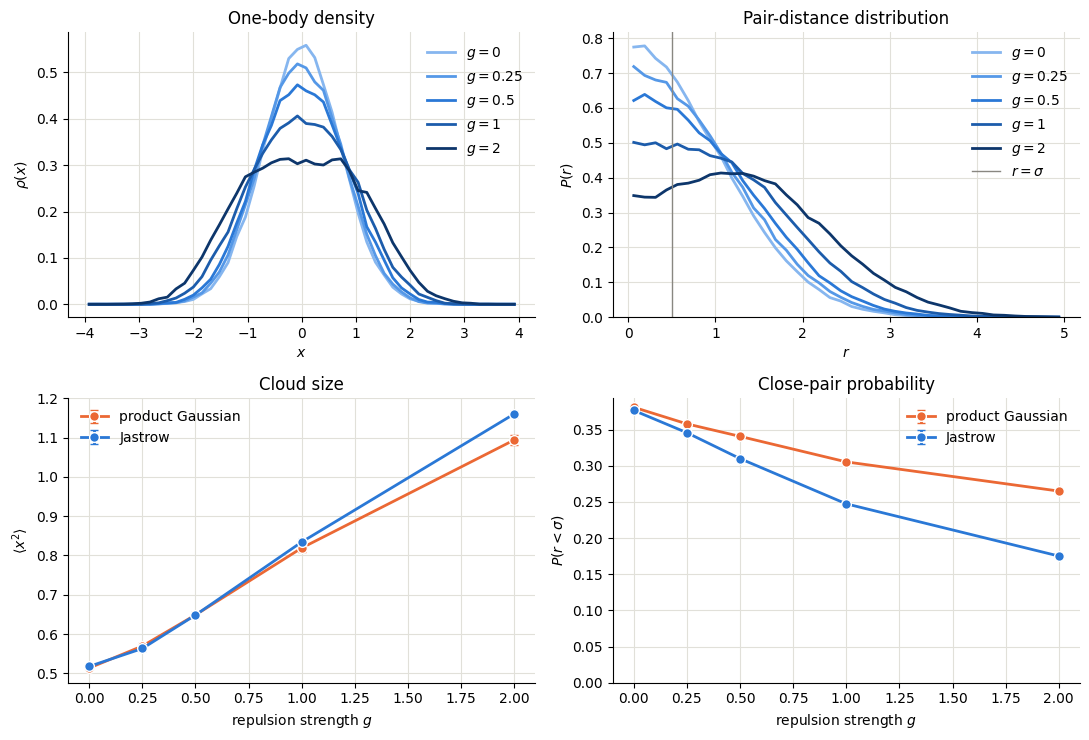

In [15]:
def one_body_density(samples, bins):
    # TODO return histogram centers and density normalized to one
    density, edges = np.histogram(samples.ravel(), bins=bins, density=True)
    centers = .5*(edges[1:] + edges[:-1])
    return centers, density

def pair_distances(samples):
    # TODO return all absolute distances |x_i - x_j| with i < j
    # shape (n_samples, n_pairs)
    i, j = np.triu_indices(samples.shape[1], k=1)
    return np.abs(samples[:, i] - samples[:, j])

def mean_square_position(samples):
    # TODO estimate <x^2> per particle
    # one value per configuration, then mean and error with the blocking of estimate_energy
    return estimate_energy(np.mean(np.power(samples,2), axis=1))

def close_pair_probability(samples, interaction_range):
    # fraction of the pairs closer than interaction_range, with its error
    return estimate_energy(np.mean(pair_distances(samples) < interaction_range, axis=1))

# Suggested scan parameters. More samples reduce histogram noise.
# coupling_values is the one of section 8.
scan_sample_count = 30000
scan_discard_count = 2000
scan_step_size = 0.8
# scan_jastrow_strength is not used: with fixed a and c the samples would not depend on g,
# so every coupling is sampled with the a and c optimized for it in section 8

# TODO sample each coupling value with a fixed Jastrow protocol.
scan_samples = []
for raw_params in jastrow_params:
    logpsi = lambda x: logpsi_interacting(raw_params, x, jastrow_range)
    scan_samples.append(sample_mcmc(logpsi, n_particles, scan_sample_count, scan_discard_count, scan_step_size))

cloud_size = np.array([mean_square_position(samples) for samples in scan_samples])
close_pairs = np.array([close_pair_probability(samples, interaction_range) for samples in scan_samples])
# same observables for the optimized product Gaussian, from the runs of section 8
product_cloud_size = np.array([mean_square_position(run[0]) for run in product_runs])
product_close_pairs = np.array([close_pair_probability(run[0], interaction_range) for run in product_runs])

print("    g   <x^2> Jastrow      <x^2> product      P(r<sigma) Jastrow   P(r<sigma) product")
for k, g in enumerate(coupling_values):
    print(f"{g:5.2f}   {cloud_size[k,0]:.3f} +- {cloud_size[k,1]:.3f}    {product_cloud_size[k,0]:.3f} +- {product_cloud_size[k,1]:.3f}"
          f"    {close_pairs[k,0]:.3f} +- {close_pairs[k,1]:.3f}      {product_close_pairs[k,0]:.3f} +- {product_close_pairs[k,1]:.3f}")

# TODO create a 2x2 panel with density, pair-distance distribution,
# TODO cloud size <x^2>, and close-pair probability P(r < sigma).
# one blue per coupling, from light (g = 0) to dark (largest g)
coupling_colors = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
(ax_rho, ax_pair), (ax_size, ax_close) = axes

for g, samples, color in zip(coupling_values, scan_samples, coupling_colors):
    centers, density = one_body_density(samples, np.linspace(-4, 4, 51))
    ax_rho.plot(centers, density, color=color, label=f"$g={g:g}$")
    pair_density, edges = np.histogram(pair_distances(samples).ravel(), bins=np.linspace(0, 5, 41), density=True)
    ax_pair.plot(.5*(edges[1:] + edges[:-1]), pair_density, color=color, label=f"$g={g:g}$")
ax_rho.set(xlabel="$x$", ylabel=r"$\rho(x)$", title="One-body density")
ax_rho.legend(frameon=False)
ax_pair.axvline(interaction_range, color=C_REF, linewidth=1, label=r"$r=\sigma$")
ax_pair.set(xlabel="$r$", ylabel="$P(r)$", title="Pair-distance distribution")
ax_pair.set_ylim(bottom=0)
ax_pair.legend(frameon=False)

ax_size.errorbar(coupling_values, product_cloud_size[:,0], yerr=product_cloud_size[:,1], fmt="o-", color=C_EXACT, markersize=7, markeredgecolor="white", capsize=3, label="product Gaussian")
ax_size.errorbar(coupling_values, cloud_size[:,0], yerr=cloud_size[:,1], fmt="o-", color=C_VMC, markersize=7, markeredgecolor="white", capsize=3, label="Jastrow")
ax_size.set(xlabel="repulsion strength $g$", ylabel=r"$\langle x^2\rangle$", title="Cloud size")
ax_size.legend(frameon=False)

ax_close.errorbar(coupling_values, product_close_pairs[:,0], yerr=product_close_pairs[:,1], fmt="o-", color=C_EXACT, markersize=7, markeredgecolor="white", capsize=3, label="product Gaussian")
ax_close.errorbar(coupling_values, close_pairs[:,0], yerr=close_pairs[:,1], fmt="o-", color=C_VMC, markersize=7, markeredgecolor="white", capsize=3, label="Jastrow")
ax_close.set(xlabel="repulsion strength $g$", ylabel=r"$P(r<\sigma)$", title="Close-pair probability")
ax_close.set_ylim(bottom=0)
ax_close.legend(frameon=False)

fig.tight_layout()
plt.show()

**What the plots show.** Every pair closer than about $\sigma$ costs an energy of order $g$, and the ground state reduces this cost in two ways.

- **Cloud broadening.** A wider cloud has a lower density and therefore fewer close pairs; the price is trap energy $\frac12\omega^2x^2$. $\rho(x)$ becomes lower and wider, and $\langle x^2\rangle$ grows from about $0.5$ at $g=0$ to about $1.15$ at $g=2$. The product Gaussian does the same with a smaller $a$ and reaches a similar size (about $1.1$).
- **Pair suppression.** At a given density the particles also avoid each other. $P(r)$ is depleted for $r\lesssim\sigma$, and at $g=2$ its maximum is no longer at $r=0$ but near $r\approx1$. $P(r<\sigma)$ falls from $0.38$ to about $0.18$, while the product Gaussian, which has no correlations and can only dilute the cloud, stops at about $0.27$. The price is kinetic energy, because the wavefunction has to bend as a function of $x_i-x_j$, so this pays off more and more as $g$ grows, consistently with the energy gain of section 8.

## 10. Going further: fermions

Bosons are indistinguishable particles with symmetric wavefunctions. Fermions are also indistinguishable, but their wavefunctions are antisymmetric:

$$
\Psi_F(\ldots,x_i,\ldots,x_j,\ldots)=-\Psi_F(\ldots,x_j,\ldots,x_i,\ldots).
$$

Therefore two identical fermions at the same position must have zero amplitude. This exchange hole is a quantum-statistical effect, not necessarily a force. A Slater determinant, possibly multiplied by a symmetric Jastrow factor, is the standard starting point. Nodes and signs mean that a globally smooth real $\log\Psi$ is unavailable, so fermionic VMC requires a separate treatment of signs or phases and encounters the fermion sign problem.

## 11. Boundary conditions and numerical domains

The harmonic, quartic, and interacting problems considered here live physically on $\mathbb{R}^N$. Their boundary condition is decay and square-integrability, not periodicity or a prescribed value at a finite wall. Explain why the trial wavefunctions used above satisfy this condition.

A finite-difference calculation of the quartic benchmark replaces $\mathbb{R}$ by $[-L,L]$ and often imposes $\psi(-L)=\psi(L)=0$. This is an artificial numerical boundary, justified only when the wavefunction is already negligible at $\pm L$. Explain why one should increase $L$ and refine the grid until the energy is stable.

The smooth Gaussian interaction does not create a cusp at particle coincidence. For fermions, by contrast, antisymmetry forces the wavefunction to vanish when two identical fermions meet. Discuss these as different kinds of boundary or nodal conditions.